# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import sys
import types
import google

colab = types.ModuleType("google.colab")
files = types.ModuleType("google.colab.files")

files.upload = lambda: None
colab.files = files

sys.modules["google.colab"] = colab
sys.modules["google.colab.files"] = files

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
import os
import shutil

os.makedirs("/content", exist_ok=True)

shutil.copy(
    os.path.join("dataset", "Lab_11_QnA_Dataset.csv"),
    "/content/Lab_11_QnA_Dataset_Download.csv"
)

print("Dataset is ready!")

Dataset is ready!


In [4]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset_Download.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [6]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [7]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [8]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

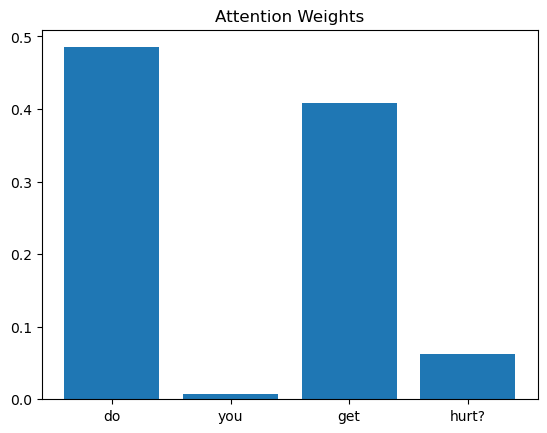

In [9]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question 1: do you get hurt?
Highest attention word: do
Attention weight: 0.4851
----------------------------------------


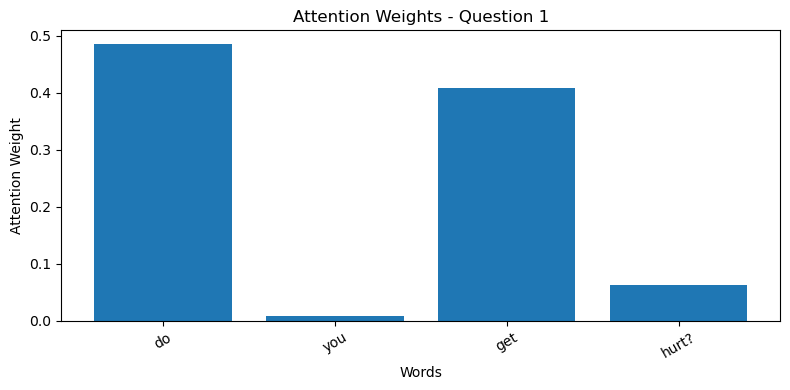

Question 2: do you have fingers?
Highest attention word: do
Attention weight: 0.8270
----------------------------------------


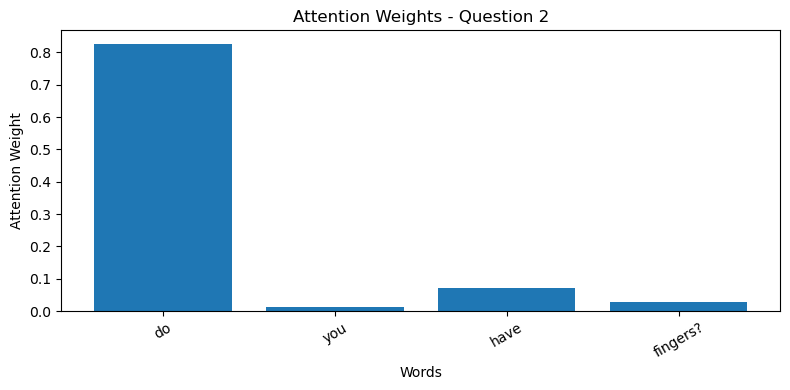

Question 3: do you ever breathe
Highest attention word: do
Attention weight: 0.6996
----------------------------------------


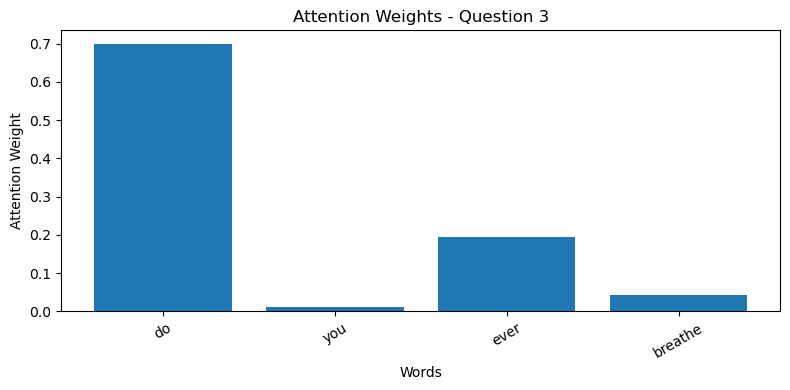

In [15]:
# Select three questions from the dataset
selected_questions = [0, 1, 2]

for i in selected_questions:

    question = df["question"].iloc[i]
    words = question.split()

    # Generate attention weights
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    # Find the word with the highest attention weight
    max_index = attention_weights.index(max(attention_weights))
    highest_word = words[max_index]

    print(f"Question {i+1}: {question}")
    print(f"Highest attention word: {highest_word}")
    print(f"Attention weight: {attention_weights[max_index]:.4f}")
    print("-" * 40)

    # Plot attention weights
    plt.figure(figsize=(8, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

**Observation:**

The results show that the word "do" received the highest attention weight in all three questions. This word is important because it helps identify the question structure. However, it does not always carry the main meaning of the question.

For example, words such as "hurt", "fingers", and "breathe" provide more specific information about the question's meaning, but they received lower attention weights.

This suggests that the model focuses strongly on the word "do", possibly because it has learned the common question pattern in the dataset. Therefore, the highest attention weights do not always correspond to the most meaningful words.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

In [16]:
display(df[["question"]].reset_index())

,index,question
0,0,do you get hurt?
1,1,do you have fingers?
2,2,do you ever breathe
3,3,do you masticate?
4,4,can you throw up?
...,...,...
163,163,that's a very clever response
164,164,that was a clever answer
165,165,that is very astute
166,166,that was a pretty intelligent answer


Question 164: that's a very clever response
Highest attention word: very
Attention weight: 0.3569
----------------------------------------


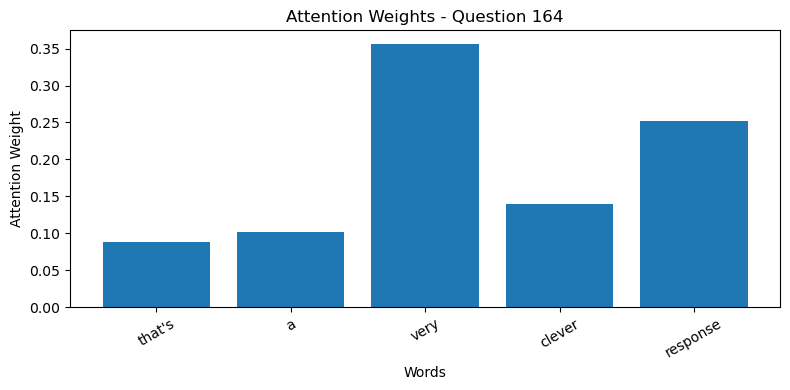

Question 165: that was a clever answer
Highest attention word: that
Attention weight: 0.3716
----------------------------------------


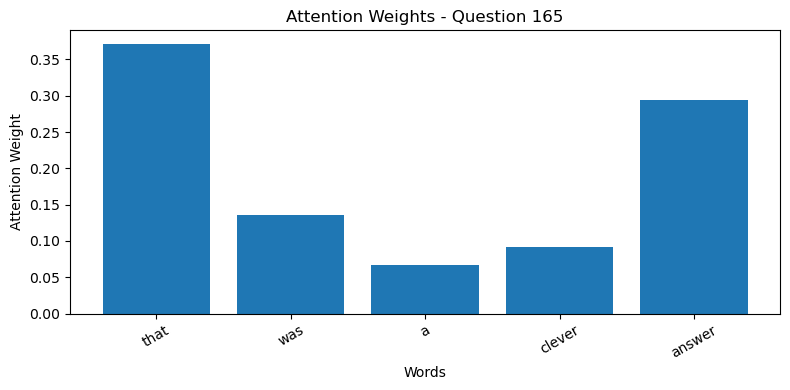

In [17]:
# Select two similar questions
selected_questions = [163, 164]

for i in selected_questions:

    question = df["question"].iloc[i]
    words = question.split()

    # Generate attention weights
    with torch.no_grad():
        prediction, weights = model(X[i:i+1])

    attention_weights = weights[0, :len(words)].tolist()

    # Find the word with the highest attention
    max_index = attention_weights.index(max(attention_weights))
    highest_word = words[max_index]

    print(f"Question {i+1}: {question}")
    print(f"Highest attention word: {highest_word}")
    print(f"Attention weight: {attention_weights[max_index]:.4f}")
    print("-" * 40)

    # Visualize attention weights
    plt.figure(figsize=(8, 4))
    plt.bar(words, attention_weights)
    plt.title(f"Attention Weights - Question {i+1}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

**Observation:**

The model focuses on different words when processing two sentences with similar meanings. In the first sentence, "very" received the highest attention weight (0.3569), while in the second sentence, "that" received the highest attention weight (0.3716).

Although both sentences express a similar meaning, the model assigns different attention weights based on their wording and context.

This suggests that attention is sensitive to the specific words and their positions in a sentence. It helps the model focus on different parts of the input rather than always selecting the same words for similar meanings.